# Dalitz fit: $\eta \to \mu^+\mu^-\gamma$

The workflow is similar to the mass fit, except organized by bins in the dalitz plot:

    read ROOT -> cuts -> best candidate -> get dalitz variables
              -> global fit_gauss -> per-dalitz-bin fits -> plots

In [1]:
import sys
import os
import json

import numpy as np
import awkward as ak
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from iminuit.cost import NormalConstraint

# Notebooks don't define __file__, so fall back to cwd (VS Code/Jupyter run
# notebooks with cwd set to the notebook's own directory).
try:
    _here = os.path.dirname(os.path.abspath(__file__))
except NameError:
    _here = os.getcwd()
for sub in ('utils', 'fit', 'plot'):
    sys.path.insert(0, os.path.join(_here, '..', sub))

import cut_utils
import kinematics
import fit_utils
import plot_utils
import plot_style
from fit_dcb import fit_dcb
from plot_dcb import plot_dcb

In [2]:
# Configuration
INFILE = '../../ntuple/lhcb/eta2mumugamma/20260608/combined_files.root'
OUTDIR = '../../out/eta2mumugamma/turbo/20260901/'
MAX_EVENTS = None      # cap on events read, for quick iteration; None = all

# Physical constraints for the Dalitz plot [GeV^2].
M_MU  = kinematics.M_MU / 1000.0
M_ETA = kinematics.M_ETA / 1000.0
M12_PHYS = (M_MU**2, (M_ETA - M_MU)**2)
M23_PHYS = ((2 * M_MU)**2, M_ETA**2)

# Branches. prt_px/py/pz/e are the Dalitz-specific addition -- a plain mass fit
# only ever needs the tag mass.
MASS_BRANCH     = 'tag_dtf_m'       # the quantity being fit
METRIC_BRANCH   = 'tag_dtf_chi2'    # ranks candidates within an event
DAUGHTER_FIELDS = ['prt_pid', 'prt_pnn_mu', 'prt_px', 'prt_py', 'prt_pz', 'prt_e']

# The decay this ntuple reconstructs. Every candidate is built to this
# composition, so it is a guarantee to assert rather than a cut to apply.
SIGNAL_DAUGHTERS = [-13, 13, 22]

# Trigger-on-signal lines OR'd together by the TOS cut. A property of this
# ntuple, not of the framework, so they live here rather than in cut_utils.
TOS_TRIGGERS = ['tag_l0_tos0', 'tag_l0_tos1', 'tag_hlt1_tos0',
                'tag_hlt1_tos1', 'tag_hlt2_tos0', 'tag_hlt2_tos1']
BRANCHES = ([MASS_BRANCH, METRIC_BRANCH, 'prt_idx_mom']
            + DAUGHTER_FIELDS + TOS_TRIGGERS)

# Selection. Set USE_TOS=False / PNN_MU_MIN=None to widen for a study.
USE_TOS    = True
PNN_MU_MIN = None

# Mass fit window. MASS_NBINS is the number of bins in the mass histogram per
# Dalitz bin. When mass candidates are sparse, decreasing this can help the fit
# converge at the cost of resolution.
# Choose SIGMA_INIT to be 
XMIN, XMAX, MASS_NBINS = 420.0, 680.0, 80
MEAN_INIT, SIGMA_INIT = M_ETA*1000.0, 10.0

# Dalitz binning. DALITZ_NBINS is the TOTAL number of Dalitz bins, so the grid is
# sqrt(DALITZ_NBINS) per dimension. It has nothing to do with MASS_NBINS above,
# and the two must never be passed to each other.
DALITZ_NBINS = 196  # 14x14 grid
M12_RANGE = (0.0, 0.21)
M23_RANGE = (0.0, 0.31)
MIN_CANDIDATES = 10    # fewer than this in a Dalitz bin -> don't attempt a fit

# Per-bin fit priors. The global fit's (mean, sigma) and (c0, c1) covariances
# are tight -- built from the whole sample -- so used raw they'd pin every
# per-bin fit to the global values instead of letting local statistics move
# them. Each prior's covariance is widened by factor**2 (factor is a stdev
# multiplier) before being used as a per-bin NormalConstraint. Background is
# expected to vary far more bin-to-bin than signal, hence the larger factor.
SIGNAL_PRIOR_FACTOR = 5
BKG_PRIOR_FACTOR = 25

os.makedirs(OUTDIR, exist_ok=True)

## Read and select

Straight out of `driver_gauss.py`: read the branches, drop events that can't be
interpreted, build a per-candidate selection mask, then reduce each event to its
single best candidate by smallest `tag_dtf_chi2`.

In [3]:
tree = cut_utils.read_branches(INFILE, BRANCHES, entry_stop=MAX_EVENTS)
tree, drop_report = cut_utils.drop_malformed(tree, tag_ref=MASS_BRANCH)

# drop_malformed derives its field lists from the branch prefixes, so every
# prt_* branch read above was checked against prt_idx_mom and every tag_*
# branch against tag_dtf_m. Nothing to remember to list.
print(f"[INFO] events: read {drop_report['read']}, kept {drop_report['kept']}, "
      f"dropped {drop_report['dropped_total']}")
for reason in ('dropped_no_candidates', 'dropped_idx_out_of_range',
               'dropped_daughter_length_mismatch',
               'dropped_partial_candidate_branch'):
    if drop_report[reason]:
        print(f'[INFO]   {reason}: {drop_report[reason]}')

n_multi = int(ak.sum(ak.num(tree[MASS_BRANCH]) > 1))
print(f'[INFO] {n_multi} / {len(tree)} events have >1 candidate')

[INFO] events: read 3711492, kept 3711492, dropped 0
[INFO] 1273604 / 3711492 events have >1 candidate


In [4]:
# Check that every candidate has exactly one of each daughter.
n_cand_total = int(ak.sum(ak.num(tree[MASS_BRANCH])))
well_formed = ak.ones_like(tree[MASS_BRANCH], dtype=bool)
for pid in SIGNAL_DAUGHTERS:
    # n = Number of daughters of this PID per candidate
    n = cut_utils.reduce(tree, tree['prt_pid'] == pid, 'prt_idx_mom',
                         how='sum', target_ref=MASS_BRANCH)
    well_formed = well_formed & (n == 1)
    print(f'[INFO] pid {pid:>4}: {float(ak.mean(ak.flatten(n))):.4f} daughters '
          f'per candidate (expected exactly 1)')

n_well_formed = int(ak.sum(well_formed))
print(f'[INFO] composition: {n_well_formed} / {n_cand_total} candidates are '
      f'exactly (mu+, mu-, gamma)')
assert n_well_formed == n_cand_total, (
    f'{n_cand_total - n_well_formed} candidates are not (mu+, mu-, gamma). '
    'That is malformed input, not background -- investigate before fitting.')

[INFO] pid  -13: 1.0000 daughters per candidate (expected exactly 1)


[INFO] pid   13: 1.0000 daughters per candidate (expected exactly 1)


[INFO] pid   22: 1.0000 daughters per candidate (expected exactly 1)
[INFO] composition: 5598421 / 5598421 candidates are exactly (mu+, mu-, gamma)


In [5]:
# Apply cuts.
keep = ak.ones_like(tree[MASS_BRANCH], dtype=bool)
tos_report = None
cutflow = [('all candidates', n_cand_total)]

# TOS only requirement.
if USE_TOS:
    tos, tos_report = cut_utils.tos_mask(tree, TOS_TRIGGERS, tag_ref=MASS_BRANCH)
    keep = keep & tos
    cutflow.append(('TOS', int(ak.sum(keep))))
    if tos_report['ignored']:
        print(f"[WARN] TOS lines absent in every event (contributing nothing): "
              f"{tos_report['ignored']}")

# ProbNNMu cut.
if PNN_MU_MIN is not None:
    # A daughter of some other PID isn't subject to a muon cut, so it can never
    # fail it. Folding that in as "passes OR isn't a muon" turns the cut into a
    # plain all-reduction onto the candidate.
    muon_ok = ((tree['prt_pnn_mu'] > PNN_MU_MIN)
               | (abs(tree['prt_pid']) != 13))
    keep = keep & cut_utils.reduce(tree, muon_ok, 'prt_idx_mom', how='all',
                                   target_ref=MASS_BRANCH)
    cutflow.append((f'pnn_mu > {PNN_MU_MIN}', int(ak.sum(keep))))

print('[INFO] cutflow (candidates surviving each cut, cumulative):')
for label, n in cutflow:
    print(f'[INFO]   {label:24s} {n:8d}')

[INFO] cutflow (candidates surviving each cut, cumulative):
[INFO]   all candidates            5598421
[INFO]   TOS                       5477385


In [6]:
# Reduce to one candidate per event.
# Get boolean mask of best candidate per event.
best = cut_utils.best_candidate_mask(tree, METRIC_BRANCH, keep)
# Apply `best` mask to the mass branch to get the list of masses to fit.
masses = cut_utils.values(tree, MASS_BRANCH, best)

assert int(ak.sum(best)) == len(masses)
assert ak.all(ak.sum(best, axis=1) <= 1), 'more than one best candidate in an event'
print(f'[INFO] {len(masses)} events kept a best candidate '
      f'(of {n_cand_total} candidates read)')

[INFO] 3639776 events kept a best candidate (of 5598421 candidates read)


## Dalitz variables

$m^2_{\gamma\mu^+}$ and $m^2_{\mu^+\mu^-}$ for each event's best candidate.
This is the piece with no framework equivalent: `cut_utils` reduces to a best
candidate and hands back a tag-level quantity, whereas the Dalitz plot needs
that candidate's individual daughter four-vectors.

In [7]:
GEV = 1000.0  # convert branches from MeV to GeV

# Convert from candidate to daughter level. `dmask` is True exactly for the
# daughters of the candidates `best` selected.
dmask = cut_utils.follow(tree, best, 'prt_idx_mom')
# Sanity check: should be three daughters per candidate
assert int(ak.sum(dmask)) == len(SIGNAL_DAUGHTERS) * len(masses)


def four_vector(pid_code):
    """(px, py, pz, e) in GeV for the daughter of this PID in each event's best
    candidate. Called once per signal daughter, hence a function.

    The composition assertion above guarantees exactly one match per selected
    candidate, so flattening gives one value per event, aligned with `masses`.
    """
    match = dmask & (tree['prt_pid'] == pid_code)
    out = tuple(ak.to_numpy(ak.flatten(tree[field][match])) / GEV
                for field in ('prt_px', 'prt_py', 'prt_pz', 'prt_e'))
    assert all(len(a) == len(masses) for a in out), (
        f'pid {pid_code}: got {len(out[0])} daughters for {len(masses)} events '
        '-- the one-per-candidate guarantee does not hold')
    return out


# Compute dalitz variables from the four-vector of the daughters.
gamma, mup, mum = (four_vector(22), four_vector(-13),
                            four_vector(13))
m12s = kinematics.invariant_mass2(*gamma, *mup)      # m^2(gamma, mu+)
m23s = kinematics.invariant_mass2(*mup, *mum)   # m^2(mu+, mu-)

# negative m^2 cannot sit on a Dalitz plot. Masking all three arrays together
# keeps them the same length by construction.
physical = (m12s > 0) & (m23s > 0)
n_unphysical = int((~physical).sum())
m12s, m23s, masses = m12s[physical], m23s[physical], masses[physical]
print(f'[INFO] dropped {n_unphysical} events with m12^2 <= 0 or m23^2 <= 0')
print(f'[INFO] {len(masses)} events into the fit')

[INFO] dropped 0 events with m12^2 <= 0 or m23^2 <= 0
[INFO] 3639776 events into the fit


In [8]:
# Print summary statistics
print('--- Dalitz plot statistics ---')
print(f'm12 range:  [{m12s.min():.4f}, {m12s.max():.4f}]  '
      f'(physical: [{M12_PHYS[0]:.4f}, {M12_PHYS[1]:.4f}])')
print(f'm23 range:  [{m23s.min():.4f}, {m23s.max():.4f}]  '
      f'(physical: [{M23_PHYS[0]:.4f}, {M23_PHYS[1]:.4f}])')
print(f'mass range: [{masses.min():.4f}, {masses.max():.4f}]')
print(f'shapes: m12s {m12s.shape}  m23s {m23s.shape}  masses {masses.shape}')
assert m12s.shape == m23s.shape == masses.shape

--- Dalitz plot statistics ---
m12 range:  [0.0119, 0.9969]  (physical: [0.0112, 0.1955])
m23 range:  [0.0447, 1.1849]  (physical: [0.0447, 0.3002])
mass range: [-5036176.3352, 4647.4329]
shapes: m12s (3639776,)  m23s (3639776,)  masses (3639776,)


## Raw Dalitz distributions

Before any fitting: what the candidates look like on the Dalitz plane, over the
full reconstructed range and zoomed into the physical region.

The helpers below are the only functions in this section -- each is called at
least twice. None of them RETURN the figure: with `%matplotlib inline` a
returned figure is rendered a second time as the cell's result, on top of the
automatic flush, which draws it twice.

In [9]:
def draw_dalitz_axes(ax):
    """Physical-boundary lines and axis labels shared by every Dalitz figure."""
    ax.axvline(M12_PHYS[0], color='red', ls='--', lw=1,
               label='physical signal window')
    ax.axvline(M12_PHYS[1], color='red', ls='--', lw=1)
    ax.axhline(M23_PHYS[0], color='red', ls='--', lw=1)
    ax.axhline(M23_PHYS[1], color='red', ls='--', lw=1)
    ax.legend(loc='upper right', fontsize=8)
    ax.set_xlabel(r'$m^2_{\gamma,\mu^+}$ [GeV$^2$]')
    ax.set_ylabel(r'$m^2_{\mu^+,\mu^-}$ [GeV$^2$]')


def plot_dalitz_hist(m12s, m23s, hist_range, title, output, bins=100):
    """Raw 2D histogram of the Dalitz variables (no fitting involved)."""
    fig, ax = plt.subplots(figsize=(8, 6))
    *_, mesh = ax.hist2d(m12s, m23s, bins=bins, cmap='viridis', range=hist_range)
    fig.colorbar(mesh, ax=ax, label='Counts')
    draw_dalitz_axes(ax)
    ax.set_title(title)
    plot_style.save_plot(fig, output)


def plot_dalitz_map(values, cbar_label, title, output):
    """Per-bin quantity (e.g. a fitted yield) drawn on the Dalitz grid."""
    fig, ax = plt.subplots(figsize=(7, 6))
    mesh = ax.pcolormesh(m12_edges, m23_edges, values.T, cmap='viridis',
                         shading='auto')
    fig.colorbar(mesh, ax=ax, label=cbar_label)
    draw_dalitz_axes(ax)
    ax.set_title(title)
    plot_style.save_plot(fig, output)


def dalitz_font():
    """House font for the Dalitz figures.

    plot_fit_data() sets font.size globally to 16 for the mass-fit plots, so
    this is re-applied whenever a Dalitz figure follows one of those.
    plt.rcdefaults() would also throw away the house font.
    """
    plot_utils.apply_font('sans')
    plt.rcParams['font.size'] = 11

[DONE] Plot saved to ../../out/eta2mumugamma/turbo/20260901/dalitz_raw.png.


[DONE] Plot saved to ../../out/eta2mumugamma/turbo/20260901/dalitz_raw_zoom.png.


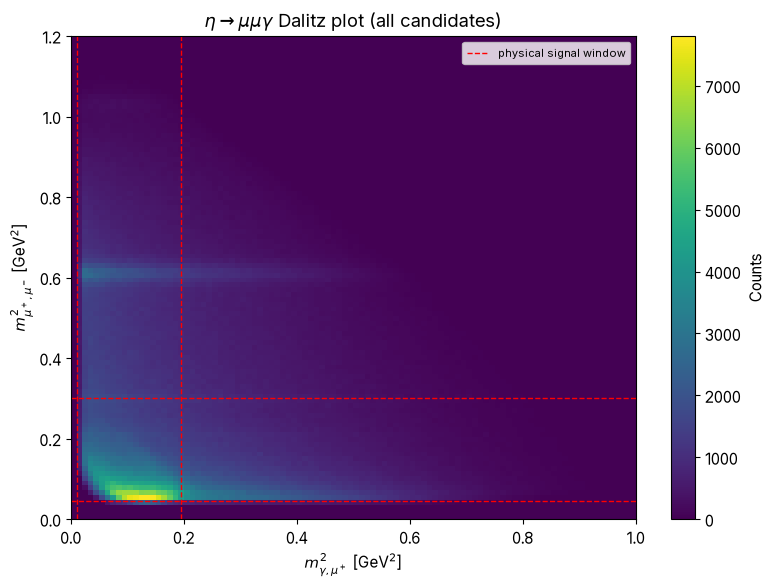

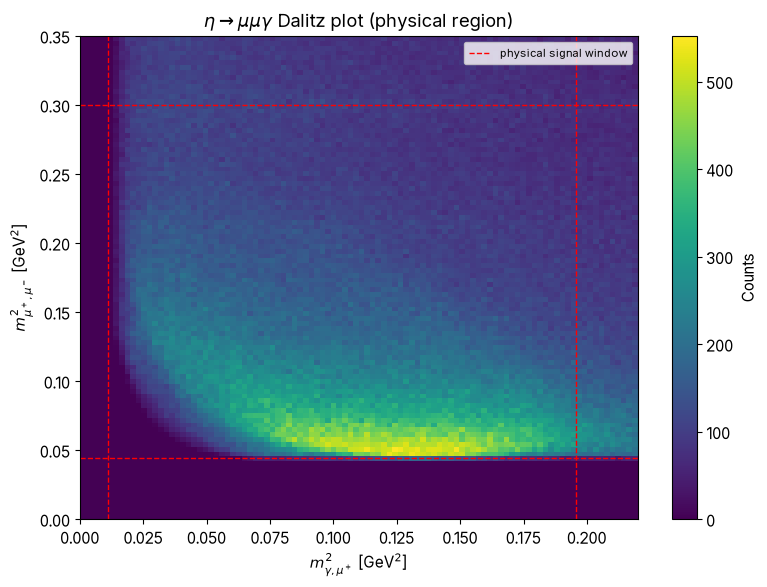

In [10]:
dalitz_font()
plot_dalitz_hist(m12s, m23s, [[0, 1.0], [0, 1.2]],
                 r'$\eta \to \mu\mu\gamma$ Dalitz plot (all candidates)',
                 os.path.join(OUTDIR, 'dalitz_raw.png'))
plot_dalitz_hist(m12s, m23s, [[0, 0.22], [0, 0.35]],
                 r'$\eta \to \mu\mu\gamma$ Dalitz plot (physical region)',
                 os.path.join(OUTDIR, 'dalitz_raw_zoom.png'))

## Global mass fit

`fit_dcb()` on the whole sample or pull values from a pre-existing fit. This
gives a prior to use for the per-bin fit, which will help with convergence. 

In [11]:
# Flag for method: do a new fit, or load a previous fit from JSON.
fit_path = None # None = do a new fit, otherwise load from this path
fit_path = "/data/home/michael24peters/anaroot/out/eta2mumugamma/turbo/20260901/results_dcb_data.json"
result, m_global = None, None
if fit_path is not None:
    with open(fit_path, 'r') as f:
        fit_result = json.load(f)
    result = fit_result
    m_global = fit_utils.LoadedFit(fit_result['fit'])
else:
    # Fit the mass distribution over all data.
    result, m_global = fit_dcb(masses, xmin=XMIN, xmax=XMAX, nbins=MASS_NBINS,
                                mean_init=MEAN_INIT, sigma_init=SIGMA_INIT)

    # Where the numbers came from -- the fit itself only ever saw an array.
    result['meta']['input_file'] = INFILE
    result['meta']['selection'] = {
        'tos': USE_TOS,
        'pnn_mu_min': PNN_MU_MIN,
        'best_candidate': f'min {METRIC_BRANCH}',
        'signal_daughters': SIGNAL_DAUGHTERS,
        'composition_asserted': True,
    }
    # Everything the selection did, so the numbers behind this fit can be audited
    # from the results file alone rather than from notebook scrollback.
    result['selection_report'] = {
        'events': drop_report,
        'triggers': tos_report,
        'cutflow': [{'cut': label, 'candidates': n} for label, n in cutflow],
        'best_candidate': {
            'metric': METRIC_BRANCH, 'method': 'min',
            'events_with_best_candidate': len(masses),
        },
        'branches_read': BRANCHES,
    }

In [12]:
# Debug: if the covariance check below fails, this says why -- which parameter
# HESSE is unhappy about, and whether it's sitting at one of its limits.
if hasattr(m_global, 'fmin'):
    print(m_global.fmin)
    for p in m_global.parameters:
        print(f'  {p:8s} value={m_global.values[p]:12.4f}  '
              f'error={m_global.errors[p]:10.4f}  limits={m_global.limits[p]}')
else:
    print('[INFO] m_global loaded from JSON -- no HESSE diagnostics (fmin/limits)')
    for p in m_global.parameters:
        print(f'  {p:8s} value={m_global.values[p]:12.4f}  error={m_global.errors[p]:10.4f}')

[INFO] m_global loaded from JSON -- no HESSE diagnostics (fmin/limits)
  mean     value=    547.8141  error=    0.0784
  sigma    value=     14.1351  error=    0.1289
  alphaL   value=      1.2075  error=    0.0312
  nL       value=      5.0654  error=    0.9542
  alphaR   value=      0.9875  error=    0.0230
  nR       value=      3.4073  error=    0.2035
  n_sig    value= 223310.5300  error= 3762.2600
  n_bkg    value= 599559.4700  error= 3798.8400
  c0       value=      0.5252  error=    0.0040
  c1       value=      0.0568  error=    0.0058


In [13]:
# Apply custom uncertainty priors. The global fit's covariance is loosened by
# SIGNAL_PRIOR_FACTOR / BKG_PRIOR_FACTOR (stdev multipliers, so variances scale
# by factor**2) before being used as a per-bin NormalConstraint below, so each
# prior is informative but not constraining.
#
# HESSE can converge on per-parameter errors while still failing to produce a
# valid *matrix* (m_global.covariance is then None) -- fall back to a diagonal
# matrix from m_global.errors in that case: no cross-parameter correlation
# term, but still a usable prior instead of a crash.

if m_global.covariance is not None:
    cov_signal = np.array(m_global.covariance[['mean', 'sigma']]) * SIGNAL_PRIOR_FACTOR**2
else:
    print('[WARN] m_global.covariance is None -- falling back to a diagonal '
          'prior from m_global.errors for (mean, sigma)')
    errs = np.array([m_global.errors['mean'], m_global.errors['sigma']])
    cov_signal = np.diag(errs**2) * SIGNAL_PRIOR_FACTOR**2

if m_global.covariance is not None:
    cov_bkg = np.array(m_global.covariance[['c0', 'c1']]) * BKG_PRIOR_FACTOR**2
else:
    print('[WARN] m_global.covariance is None -- falling back to a diagonal '
          'prior from m_global.errors for (c0, c1)')
    errs = np.array([m_global.errors['c0'], m_global.errors['c1']])
    cov_bkg = np.diag(errs**2) * BKG_PRIOR_FACTOR**2

[DONE] Plot saved to ../../out/eta2mumugamma/turbo/20260901/global_gauss_fit.png.

────────────────────────────────────────────────
                Fit summary                 
────────────────────────────────────────────────
μ = 547.81 ± 0.08 MeV
σ = 14.14 ± 0.13 MeV
α_L = 1.21 ± 0.03, n_L = 5.1 ± 1.0
α_R = 0.99 ± 0.02, n_R = 3.41 ± 0.20
n_sig = 223311 ± 3762
n_bkg = 599559 ± 3799
c_0 = 0.53 ± 0.00, c_1 = 0.06 ± 0.01
χ²/ndof = 1.78
────────────────────────────────────────────────
[INFO] per-bin seeds: mean=547.814  sigma=14.135  c0=0.525  c1=0.057
[INFO] per-bin fixed tails: alphaL=1.207  nL=5.065  alphaR=0.987  nR=3.407


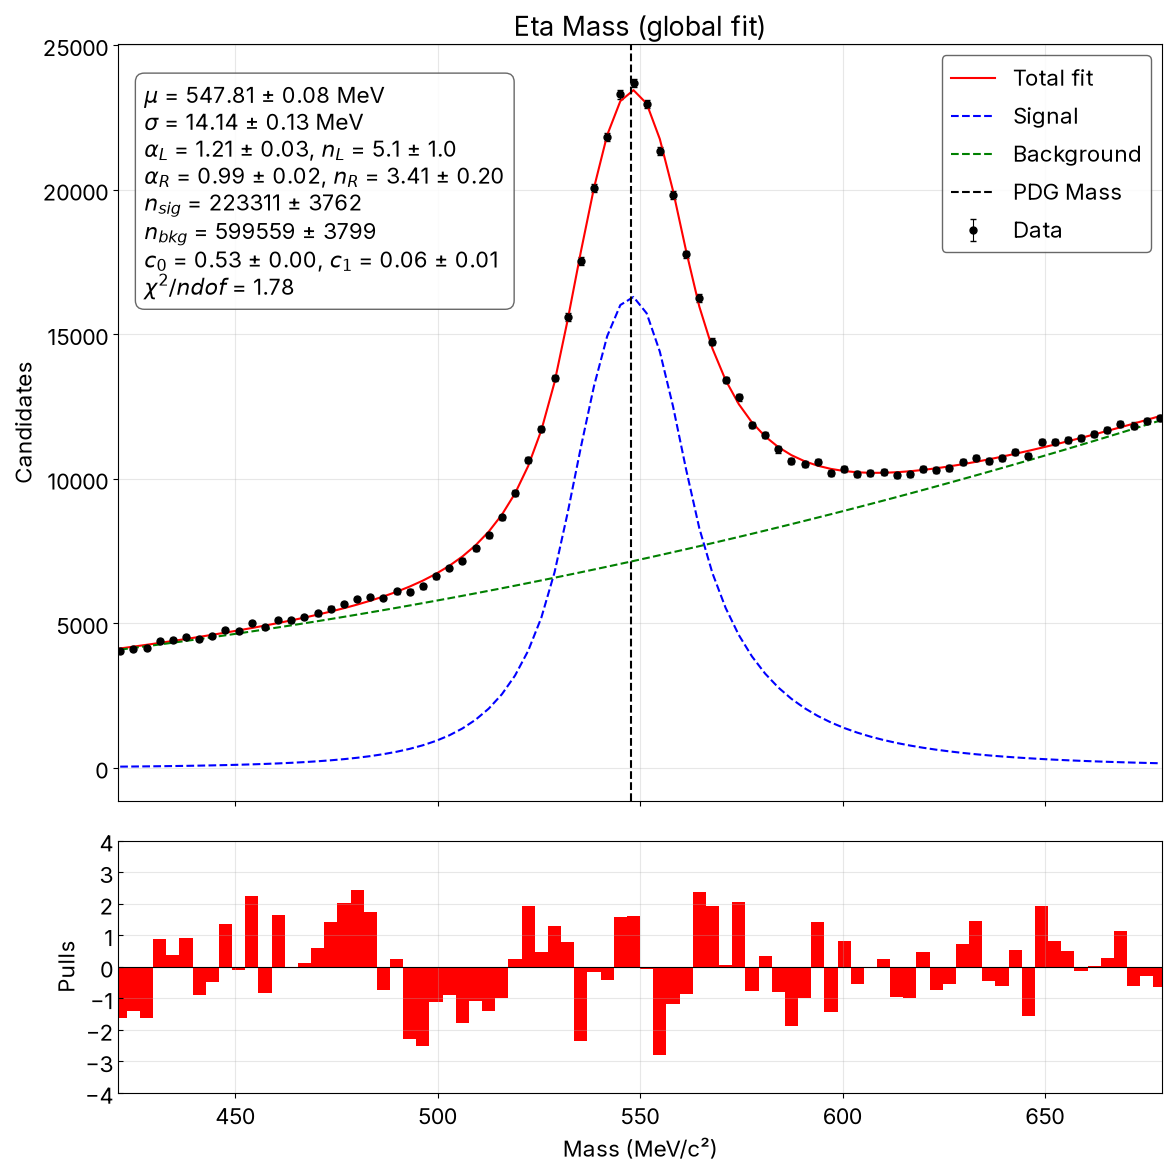

In [14]:
# plot_gauss layers its DEFAULT_CONFIG (house font, stats box, pull panel) under
# these overrides -- the same call driver_gauss.py makes.
plot_dcb(result, {'output': os.path.join(OUTDIR, 'global_gauss_fit.png'),
                    'title': 'Eta Mass (global fit)'})

# Seed the per-bin fits from the global fit. Tail shape params are held
# fixed at these values per bin -- too few candidates per Dalitz bin to float
# a 10-parameter DCB, so only mean, sigma, n_sig, n_bkg, c0, c1 float.
mean_init   = result['fit']['parameters']['mean']['value']
sigma_init  = result['fit']['parameters']['sigma']['value']
alphaL_init = result['fit']['parameters']['alphaL']['value']
nL_init     = result['fit']['parameters']['nL']['value']
alphaR_init = result['fit']['parameters']['alphaR']['value']
nR_init     = result['fit']['parameters']['nR']['value']
c0_init     = result['fit']['parameters']['c0']['value']
c1_init     = result['fit']['parameters']['c1']['value']
print(f'[INFO] per-bin seeds: mean={mean_init:.3f}  sigma={sigma_init:.3f}  '
      f'c0={c0_init:.3f}  c1={c1_init:.3f}')
print(f'[INFO] per-bin fixed tails: alphaL={alphaL_init:.3f}  nL={nL_init:.3f}  '
      f'alphaR={alphaR_init:.3f}  nR={nR_init:.3f}')

## Per-Dalitz-bin fits

`fit_dcb()` fits one array and returns a JSON-shaped dict; that is the right
shape for a single global fit, but a few hundred per-bin fits only need the
Minuit object. So the loop below drops one level and calls `fit_utils` directly
-- the same `make_dcb_cost` / `run_fit` pair `fit_dcb()` itself uses, so the
global fit and the per-bin fits are the same DCB + Chebyshev model applied to
different subsets. Each bin only has a few tens of candidates, too few to float
all 10 DCB parameters, so the tail shape (alphaL, nL, alphaR, nR) is held fixed
at the global fit's values and only mean, sigma, n_sig, n_bkg, c0, c1 float.

**Goodness of fit.** Neyman (data-based): $\chi^2 = \sum (d-f)^2/d$ and
pulls $(d-f)/\sqrt{d}$, so $\sum \mathrm{pull}^2$ equals the reported
$\chi^2$. The denominator is the measurement uncertainty rather than a fit
uncertainty. `fit_gauss` and `fit_dcb` now use the same convention.

Only `dalitz_bin_mask` (3 callers) and `bin_prediction` (2 callers) are
functions here; the fitting loop itself is inline.

In [15]:
# Mass histogram binning, used by every per-bin fit AND every per-bin plot.
# Defined once so the two provably agree.
MASS_EDGES = np.linspace(XMIN, XMAX, MASS_NBINS + 1)
MASS_CENTERS = 0.5 * (MASS_EDGES[:-1] + MASS_EDGES[1:])
MASS_BIN_WIDTH = (XMAX - XMIN) / MASS_NBINS

n_per_dim = int(np.sqrt(DALITZ_NBINS))
# Dalitz grid. DALITZ_NBINS is the TOTAL count, so the grid is sqrt(it) a side.
# Equal width edges
m12_edges = np.linspace(*M12_RANGE, n_per_dim + 1)
m23_edges = np.linspace(*M23_RANGE, n_per_dim + 1)

# Equal-population edges, so now convergence should work across the whole grid.
# _in_grid = ((m12s >= M12_RANGE[0]) & (m12s < M12_RANGE[1]) &
#             (m23s >= M23_RANGE[0]) & (m23s < M23_RANGE[1]))
# _q = np.linspace(0.0, 1.0, n_per_dim + 1)
# m12_edges = np.quantile(m12s[_in_grid], _q)
# m23_edges = np.quantile(m23s[_in_grid], _q)
# # Pin the outer edges so the grid covers the declared ranges exactly.
# m12_edges[0], m12_edges[-1] = M12_RANGE
# m23_edges[0], m23_edges[-1] = M23_RANGE

def dalitz_bin_mask(i, j):
    """Half-open [lo, hi) mask selecting Dalitz bin (i, j).

    The fits, the results JSON and the per-bin plots all go through this, so a
    page always shows the candidates its own fit saw.
    """
    return ((m12s >= m12_edges[i]) & (m12s < m12_edges[i + 1]) &
            (m23s >= m23_edges[j]) & (m23s < m23_edges[j + 1]))


def bin_prediction(fit_result, counts):
    """Expected counts, data-based pulls and chi2/ndf for one bin's fit.

    Called by the results JSON and by the per-bin plots. Uses the same
    fit_utils CDFs the cost function used, so what gets drawn and reported is
    the fit, not a re-derivation of it.
    """
    p = fit_result.values
    n_sig, n_bkg = float(p['n_sig']), float(p['n_bkg'])
    bin_sig = np.diff(fit_utils.dcb_cdf(MASS_EDGES, XMIN, XMAX, p['mean'], p['sigma'],
                                        p['alphaL'], p['nL'], p['alphaR'], p['nR'])) * n_sig
    bin_bkg = np.diff(fit_utils.cheb_cdf(MASS_EDGES, XMIN, XMAX,
                                         p['c0'], p['c1'])) * n_bkg
    bin_fit = bin_sig + bin_bkg

    # Neyman (data-based) chi2 and pulls: the DATA is the variance estimate, so
    # sum(pulls**2) == chi2. Matches fit_gauss.py and fit_dcb.py. Empty-DATA
    # bins are skipped and don't count toward ndof.
    ok = counts > 0
    pulls = np.where(ok, (counts - bin_fit) / np.sqrt(np.where(ok, counts, 1.0)), 0.0)
    chi2 = float(np.sum((counts[ok] - bin_fit[ok])**2 / counts[ok]))
    ndof = int(ok.sum()) - fit_result.nfit
    return {
        'n_sig': n_sig, 'n_bkg': n_bkg, 'bin_fit': bin_fit, 'pulls': pulls,
        'chi2': chi2, 'ndof': ndof,
        'chi2_per_ndof': chi2 / ndof if ndof > 0 else float('nan'),
    }

In [16]:
# One DCB + Chebyshev fit per Dalitz bin, tails fixed from the global fit.
# Bins with too few candidates are thrown out. The fit results are stored in
# a dict keyed by (i, j) bin index.

# Both signal and background shapes are softly constrained toward the global
# fit via cov_signal / cov_bkg (computed above), not fixed -- the background
# constraint is far looser than the signal one so it can still vary a lot
# across the Dalitz plot.

fit_results = {}
for i in range(n_per_dim):
    for j in range(n_per_dim):
        masses_in_bin = masses[dalitz_bin_mask(i, j)]
        if len(masses_in_bin) <= MIN_CANDIDATES: continue

        counts, edges = np.histogram(masses_in_bin, bins=MASS_EDGES)
        counts = counts.astype(float)
        n_cand = counts.sum()

        cost = fit_utils.make_dcb_cost(counts, edges, XMIN, XMAX)
        cost = cost + NormalConstraint(('c0', 'c1'), (c0_init, c1_init),
                                       error=cov_bkg)
        cost = cost + NormalConstraint(('mean', 'sigma'), (mean_init, 
                                       sigma_init), error=cov_signal)
        init = dict(mean=mean_init, sigma=sigma_init,
                    alphaL=alphaL_init, nL=nL_init,
                    alphaR=alphaR_init, nR=nR_init,
                    n_sig=n_cand * 0.5, n_bkg=n_cand * 0.5, c0=c0_init, c1=c1_init)
        limits = dict(sigma=(0.0, None), alphaL=(0.0, None), alphaR=(0.0, None),
                      nL=(0.0, None), nR=(0.0, None),
                      n_sig=(0.0, None), n_bkg=(0.0, None))
        # Tails are fixed at the global fit's values -- too few candidates per
        # bin to float all 10 DCB params; only the core and yields move.
        m = fit_utils.run_fit(cost, init, limits,
                              fixed=['alphaL', 'nL', 'alphaR', 'nR'])

        fit_results[(i, j)] = {
            'fit': m,
            'n_cand': n_cand,
            'n_events': len(masses_in_bin),
            'm12_range': (m12_edges[i], m12_edges[i + 1]),
            'm23_range': (m23_edges[j], m23_edges[j + 1]),
        }

# Yield maps. A bin never fit, or whose fit failed, stays 0 -- the checks below
# tell those two apart. n_bkg is a free fit parameter, so read it from the fit
# rather than deriving it as n_cand - n_sig.
signal_counts = np.zeros((n_per_dim, n_per_dim))
bkg_counts = np.zeros((n_per_dim, n_per_dim))
for (i, j), r in fit_results.items():
    if not r['fit'].valid: continue
    signal_counts[i, j] = r['fit'].values['n_sig']
    bkg_counts[i, j] = r['fit'].values['n_bkg']

print(f'[INFO] fitted {len(fit_results)} / {n_per_dim**2} Dalitz bins')

[INFO] fitted 164 / 196 Dalitz bins


## Fit sanity checks

In [17]:
# A hole (yield = 0) happens either because there were too few candidates to
# attempt a fit, or because the fit ran and failed to converge. An isolated hole
# is the former; a hole surrounded by well-populated bins is the latter.
skipped, invalid, valid = [], [], []
for i in range(n_per_dim):
    for j in range(n_per_dim):
        if (i, j) not in fit_results:              skipped.append((i, j))
        elif not fit_results[(i, j)]['fit'].valid: invalid.append((i, j))
        else:                                      valid.append((i, j))

print(f'--- Per-bin fit outcome ({n_per_dim}x{n_per_dim} = '
      f'{n_per_dim**2} Dalitz bins) ---')
print(f'  skipped (<= {MIN_CANDIDATES} raw candidates): {len(skipped)}')
print(f'  fit invalid (hole):                {len(invalid)}')
print(f'  fit valid:                         {len(valid)}')

if invalid:
    print("\n--- Raw candidate counts at 'invalid fit' holes ---")
    print('(large n_cand means the hole is a fit-convergence failure)')
    for (i, j) in invalid:
        print(f"  bin ({i:2d},{j:2d}): n_cand={fit_results[(i, j)]['n_cand']:8.0f}")

--- Per-bin fit outcome (14x14 = 196 Dalitz bins) ---
  skipped (<= 10 raw candidates): 32
  fit invalid (hole):                39
  fit valid:                         125

--- Raw candidate counts at 'invalid fit' holes ---
(large n_cand means the hole is a fit-convergence failure)
  bin ( 1, 4): n_cand=    1379
  bin ( 1, 6): n_cand=    5414
  bin ( 2, 5): n_cand=    8577
  bin ( 2,12): n_cand=    3068
  bin ( 2,13): n_cand=    2625
  bin ( 3,10): n_cand=    3838
  bin ( 3,12): n_cand=    2490
  bin ( 4,10): n_cand=    3243
  bin ( 4,11): n_cand=    2505
  bin ( 5,10): n_cand=    2664
  bin ( 5,12): n_cand=    1863
  bin ( 5,13): n_cand=    1629
  bin ( 6, 8): n_cand=    4116
  bin ( 6,10): n_cand=    2326
  bin ( 6,11): n_cand=    1850
  bin ( 7, 6): n_cand=    5573
  bin ( 7,12): n_cand=    1344
  bin ( 8, 6): n_cand=    5245
  bin ( 8, 9): n_cand=    2164
  bin ( 9, 3): n_cand=   12215
  bin ( 9, 5): n_cand=    6270
  bin ( 9, 7): n_cand=    3129
  bin ( 9, 8): n_cand=    2178
  b

In [18]:
# --- B: is the fitted background shape physical? -----------------------------
# c0/c1 float per Dalitz bin (only mean and sigma are fixed). The 2nd-order
# Chebyshev background is NOT guaranteed non-negative over [XMIN, XMAX] for
# every (c0, c1) inside its allowed box: c0 near +/-1 together with c1 near
# -/+1.4 pushes the curve below zero at one edge of the window. A per-bin fit
# can land there and still report valid == True, so this catches "quietly
# wrong" bins the holes-only check misses -- they show up not as 0 in the yield
# map, but as a bogus nonzero yield.
x_check = np.linspace(XMIN, XMAX, 200)
neg_bkg_bins = []
for (i, j) in valid:
    r = fit_results[(i, j)]['fit']
    if np.any(fit_utils.cheb_bkg_pdf(x_check, XMIN, XMAX,
                                     r.values['c0'], r.values['c1']) < 0):
        neg_bkg_bins.append((i, j))

print('--- Background positivity check (valid fits only) ---')
print(f'{len(neg_bkg_bins)} / {len(valid)} valid fits have a background curve '
      f'that goes negative somewhere in [XMIN, XMAX].')
for (i, j) in neg_bkg_bins[:10]:
    r = fit_results[(i, j)]['fit']
    print(f"  ({i:2d},{j:2d}): c0={r.values['c0']:.3f}  c1={r.values['c1']:.3f}")

--- Background positivity check (valid fits only) ---
97 / 125 valid fits have a background curve that goes negative somewhere in [XMIN, XMAX].
  ( 1, 3): c0=0.336  c1=1.055
  ( 1, 5): c0=-1.510  c1=0.656
  ( 1, 7): c0=-1.335  c1=-0.107
  ( 1, 8): c0=-0.930  c1=-1.519
  ( 1, 9): c0=0.101  c1=-0.996
  ( 1,10): c0=0.836  c1=-0.727
  ( 1,11): c0=1.331  c1=-0.091
  ( 1,12): c0=1.535  c1=0.178
  ( 1,13): c0=1.515  c1=0.554
  ( 2, 2): c0=0.120  c1=1.157


In [19]:
# If a hole's raw n_cand is comparable to its immediate neighbors', the 0 in the
# yield map is a fit-convergence issue.
raw = np.full((n_per_dim, n_per_dim), np.nan)
for (i, j), r in fit_results.items():
    raw[i, j] = r['n_cand']

print('--- Neighbor comparison for holes (raw n_cand) ---')
if not invalid:
    print('No holes from non-convergence this run.')
for (i, j) in invalid:
    neighbors = {(di, dj): raw[i + di, j + dj]
                 for di, dj in [(-1, 0), (1, 0), (0, -1), (0, 1)]
                 if 0 <= i + di < n_per_dim and 0 <= j + dj < n_per_dim
                 and not np.isnan(raw[i + di, j + dj])}
    if neighbors:
        neighbor_str = ', '.join(f'{k}: {v:.0f}' for k, v in neighbors.items())
        print(f'  hole ({i:2d},{j:2d}): n_cand={raw[i, j]:.0f}  '
              f'neighbors: {neighbor_str}')

--- Neighbor comparison for holes (raw n_cand) ---
  hole ( 1, 4): n_cand=1379  neighbors: (1, 0): 6736, (0, -1): 140, (0, 1): 3352
  hole ( 1, 6): n_cand=5414  neighbors: (-1, 0): 29, (1, 0): 8728, (0, -1): 3352, (0, 1): 6232
  hole ( 2, 5): n_cand=8577  neighbors: (-1, 0): 3352, (1, 0): 9444, (0, -1): 6736, (0, 1): 8728
  hole ( 2,12): n_cand=3068  neighbors: (-1, 0): 3199, (1, 0): 2490, (0, -1): 3576, (0, 1): 2625
  hole ( 2,13): n_cand=2625  neighbors: (-1, 0): 2928, (1, 0): 2192, (0, -1): 3068
  hole ( 3,10): n_cand=3838  neighbors: (-1, 0): 4474, (1, 0): 3243, (0, -1): 4622, (0, 1): 3052
  hole ( 3,12): n_cand=2490  neighbors: (-1, 0): 3068, (1, 0): 2114, (0, -1): 3052, (0, 1): 2192
  hole ( 4,10): n_cand=3243  neighbors: (-1, 0): 3838, (1, 0): 2664, (0, -1): 4150, (0, 1): 2505
  hole ( 4,11): n_cand=2505  neighbors: (-1, 0): 3052, (1, 0): 2173, (0, -1): 3243, (0, 1): 2114
  hole ( 5,10): n_cand=2664  neighbors: (-1, 0): 3243, (1, 0): 2326, (0, -1): 3722, (0, 1): 2173
  hole ( 5,

In [20]:
# The per-bin fits carve up the same sample the global fit saw, so their yields
# should sum to roughly the global numbers, short by the out-of-grid fraction.
# A large discrepancy means bins are being skipped or double-counted, which
# none of the checks above would catch.
n_sig_global = result['fit']['parameters']['n_sig']['value']
n_bkg_global = result['fit']['parameters']['n_bkg']['value']
in_grid = ((m12s >= M12_RANGE[0]) & (m12s < M12_RANGE[1]) &
           (m23s >= M23_RANGE[0]) & (m23s < M23_RANGE[1]))

print('--- Global vs summed per-bin yields ---')
print(f'  candidates in the Dalitz grid : {int(in_grid.sum())} / {len(masses)}'
      f'  ({100 * in_grid.mean():.1f}%)')
print(f'  n_sig  global {n_sig_global:10.1f}   summed {signal_counts.sum():10.1f}')
print(f'  n_bkg  global {n_bkg_global:10.1f}   summed {bkg_counts.sum():10.1f}')

--- Global vs summed per-bin yields ---
  candidates in the Dalitz grid : 1083166 / 3639776  (29.8%)
  n_sig  global   223310.5   summed   218330.1
  n_bkg  global   599559.5   summed   378709.6


## Fitted yield maps

The Dalitz plot the fits were for: signal and background yields per bin, rather
than raw candidate counts.

[DONE] Plot saved to ../../out/eta2mumugamma/turbo/20260901/dalitz_signal_yield.png.


[DONE] Plot saved to ../../out/eta2mumugamma/turbo/20260901/dalitz_bkg_yield.png.


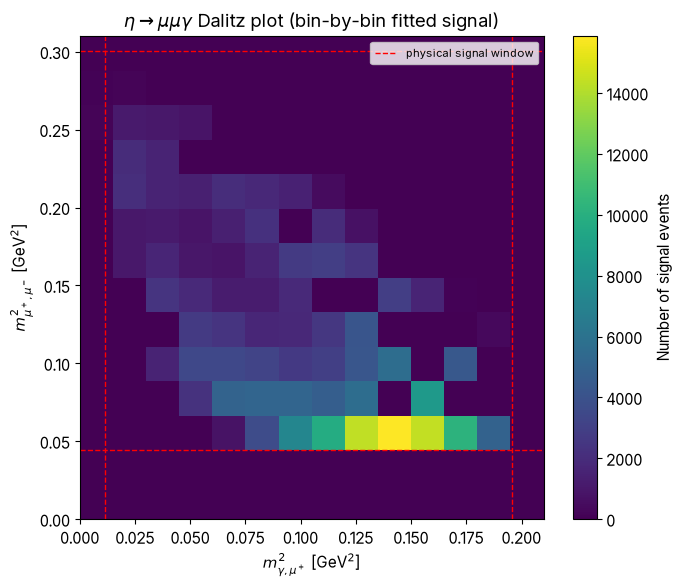

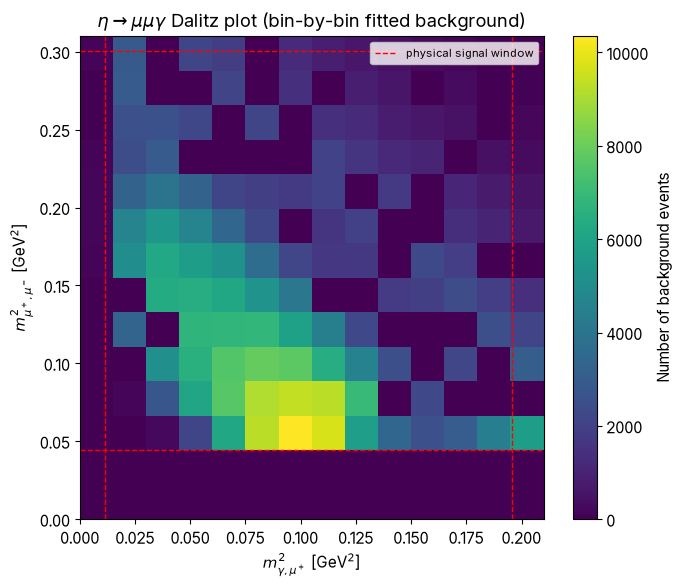

In [21]:
dalitz_font()
plot_dalitz_map(signal_counts, 'Number of signal events',
                r'$\eta \to \mu\mu\gamma$ Dalitz plot (bin-by-bin fitted signal)',
                os.path.join(OUTDIR, 'dalitz_signal_yield.png'))
plot_dalitz_map(bkg_counts, 'Number of background events',
                r'$\eta \to \mu\mu\gamma$ Dalitz plot (bin-by-bin fitted background)',
                os.path.join(OUTDIR, 'dalitz_bkg_yield.png'))

## Results file

The global fit dict from `fit_gauss()` plus a `dalitz` section recording the
per-bin outcome, in the same spirit as `results_gauss.json`: enough to audit the
numbers without the notebook.

In [22]:
bins = []
for (i, j) in sorted(fit_results):
    r = fit_results[(i, j)]
    fit_result = r['fit']
    entry = {
        'i': i, 'j': j,
        'm12_range': [float(v) for v in r['m12_range']],
        'm23_range': [float(v) for v in r['m23_range']],
        'n_cand': float(r['n_cand']),
        'n_events': int(r['n_events']),
        'valid': bool(fit_result.valid),
    }
    if fit_result.valid:
        # Recount from the same mask the fit used, so chi2 here is the chi2 of
        # the histogram that was fit.
        counts, _ = np.histogram(masses[dalitz_bin_mask(i, j)], bins=MASS_EDGES)
        pred = bin_prediction(fit_result, counts.astype(float))
        entry.update({
            'n_sig': round(pred['n_sig'], 2),
            'n_sig_err': round(float(fit_result.errors['n_sig']), 2),
            'n_bkg': round(pred['n_bkg'], 2),
            'n_bkg_err': round(float(fit_result.errors['n_bkg']), 2),
            'c0': round(float(fit_result.values['c0']), 6),
            'c1': round(float(fit_result.values['c1']), 6),
            'chi2': round(pred['chi2'], 4),
            'ndof': pred['ndof'],
            'chi2_per_ndof': round(pred['chi2_per_ndof'], 6),
            'bkg_goes_negative': (i, j) in neg_bkg_bins,
        })
    bins.append(entry)

result['dalitz'] = {
    'm12_edges': m12_edges.tolist(),
    'm23_edges': m23_edges.tolist(),
    'nbins_total': DALITZ_NBINS,
    'nbins_per_dim': n_per_dim,
    'mass_window': {'xmin': XMIN, 'xmax': XMAX, 'nbins': MASS_NBINS},
    'min_candidates': MIN_CANDIDATES,
    'chi2_convention': 'neyman/data-based: sum (d - f)^2 / d',
    'pull_convention': 'data-based: (d - f) / sqrt(d)',
    'seeded_from_global_fit': ['mean', 'sigma', 'c0', 'c1'],
    'fixed_in_per_bin_fit': ['mean', 'sigma'],
    'events_dropped_unphysical_m2': n_unphysical,
    'outcome': {'skipped': len(skipped), 'invalid': len(invalid),
                'valid': len(valid)},
    'yield_closure': {
        'n_sig_global': n_sig_global, 'n_sig_summed': float(signal_counts.sum()),
        'n_bkg_global': n_bkg_global, 'n_bkg_summed': float(bkg_counts.sum()),
        'candidates_in_grid': int(in_grid.sum()), 'candidates_total': len(masses),
    },
    'bins': bins,
}

json_path = os.path.join(OUTDIR, 'dalitz_fit_results.json')
with open(json_path, 'w') as f:
    json.dump(result, f, indent=2)
print(f'[DONE] JSON saved to: {json_path}')

[DONE] JSON saved to: ../../out/eta2mumugamma/turbo/20260901/dalitz_fit_results.json


## Per-bin mass spectra

One page per Dalitz bin, so every yield in the maps above can be traced back to
the fit that produced it. Every bin gets a page -- including the ones that were
skipped and the ones whose fit didn't converge. A missing fit says nothing about
the data, and a page showing the data with no curve on it is exactly what tells
"this bin is empty" apart from "this bin has data the fit couldn't handle".

In [23]:
# PdfPages is the file, so it is opened ONCE outside the loop -- constructing it
# per iteration reopens and truncates the same path, leaving a 1-page PDF. The
# `with` block also writes the page tree even if a bin raises partway through.
dalitz_font()
pdf_path = os.path.join(OUTDIR, 'per_bin_fits.pdf')
n_pages = n_fitted = 0

with PdfPages(pdf_path) as pdf:
    for i in range(n_per_dim):
        for j in range(n_per_dim):
            # Same mask the fit used, so the page shows the same candidates.
            mask = dalitz_bin_mask(i, j)
            counts = np.histogram(masses[mask], bins=MASS_EDGES)[0].astype(float)
            # .get() -> None for bins that were never fit at all.
            r = fit_results.get((i, j))
            fit_result = r['fit'] if r is not None else None
            has_fit = fit_result is not None and fit_result.valid

            # Fixed two-panel geometry on every page (spectrum + pulls) so the
            # pages stay comparable when flipping through a few hundred.
            fig, (ax, ax_pull) = plt.subplots(
                2, 1, figsize=(8, 6.5), sharex=True,
                gridspec_kw={'height_ratios': [3, 1], 'hspace': 0.07})

            # Data as points with Poisson error bars, not a filled histogram:
            # the point of these pages is judging how well a curve tracks the
            # data given the per-bin statistics.
            ax.errorbar(MASS_CENTERS, counts, yerr=np.sqrt(counts), fmt='o',
                        ms=2.5, lw=1, color='black', label='Data', zorder=3)

            if has_fit:
                p = fit_result.values
                pred = bin_prediction(fit_result, counts)
                # Smooth curves for display: unit-normalized PDFs scaled by
                # their yield and the bin width to land on the counts scale.
                x_fit = np.linspace(XMIN, XMAX, 400)
                y_sig = pred['n_sig'] * MASS_BIN_WIDTH * fit_utils.dcb_pdf(
                    x_fit, XMIN, XMAX, p['mean'], p['sigma'],
                    p['alphaL'], p['nL'], p['alphaR'], p['nR'])
                y_bkg = pred['n_bkg'] * MASS_BIN_WIDTH * fit_utils.cheb_bkg_pdf(
                    x_fit, XMIN, XMAX, p['c0'], p['c1'])
                ax.plot(x_fit, y_sig + y_bkg, color='red', lw=1.5, label='Fit',
                        zorder=2)
                ax.plot(x_fit, y_bkg, color='green', ls='--', lw=1.2,
                        label='Background', zorder=2)

                ax_pull.bar(MASS_CENTERS, pred['pulls'], width=MASS_BIN_WIDTH,
                            color='red', edgecolor='none')
                for y in (-2, 2): ax_pull.axhline(y, color='gray', ls=':', lw=0.8)

                status = (f"n_cand = {r['n_cand']:.0f}\n"
                          f"n_sig  = {pred['n_sig']:.1f} $\\pm$ "
                          f"{fit_result.errors['n_sig']:.1f}\n"
                          f"n_bkg  = {pred['n_bkg']:.1f} $\\pm$ "
                          f"{fit_result.errors['n_bkg']:.1f}\n"
                          f"c0 = {p['c0']:.3f}   c1 = {p['c1']:.3f}\n"
                          f"$\\chi^2$/ndf = {pred['chi2_per_ndof']:.2f}")
                box_color = 'black'
            else:
                # No curve to draw: say why, and leave the pull panel blank
                # rather than faking residuals against a fit that doesn't exist.
                if r is None:
                    status = (f'NO FIT ATTEMPTED\n{int(mask.sum())} candidates '
                              f'(threshold is {MIN_CANDIDATES})')
                else:
                    status = f"FIT DID NOT CONVERGE\nn_cand = {r['n_cand']:.0f}"
                ax_pull.text(0.5, 0.5, 'no fit', transform=ax_pull.transAxes,
                             ha='center', va='center', color='gray', fontsize=9)
                box_color = 'red'

            ax_pull.set_ylim(-5, 5)
            ax.text(0.02, 0.97, status, transform=ax.transAxes, va='top',
                    ha='left', fontsize=8, family='monospace', color=box_color,
                    bbox=dict(boxstyle='round', fc='white', ec=box_color,
                              alpha=0.8))
            ax.set_title(f'Bin ({i}, {j}): '
                         f'm12=[{m12_edges[i]:.4f}, {m12_edges[i + 1]:.4f}], '
                         f'm23=[{m23_edges[j]:.4f}, {m23_edges[j + 1]:.4f}]')
            ax.set_ylabel(f'Counts / {MASS_BIN_WIDTH:.2f} MeV')
            ax.set_xlim(XMIN, XMAX)
            ax.legend(loc='upper right', fontsize=8)
            ax_pull.set_xlabel('Mass [MeV]')
            ax_pull.set_ylabel('Pull (data-based)')

            # One page per bin, then close so a few hundred figures don't all
            # stay resident in memory.
            pdf.savefig(fig)
            plt.close(fig)
            n_pages += 1
            n_fitted += int(has_fit)

print(f'Wrote {n_pages} pages to {pdf_path} '
      f'({n_fitted} with a fit, {n_pages - n_fitted} data-only)')

Wrote 196 pages to ../../out/eta2mumugamma/turbo/20260901/per_bin_fits.pdf (125 with a fit, 71 data-only)
